<a href="https://colab.research.google.com/github/maryamashraf6565-star/Email_spam_detector/blob/main/email_spamer_detector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

In [6]:
df = pd.read_csv('/spam.csv', encoding='latin-1')
print(df)

        v1                                                 v2 Unnamed: 2  \
0      ham  Go until jurong point, crazy.. Available only ...        NaN   
1      ham                      Ok lar... Joking wif u oni...        NaN   
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...        NaN   
3      ham  U dun say so early hor... U c already then say...        NaN   
4      ham  Nah I don't think he goes to usf, he lives aro...        NaN   
...    ...                                                ...        ...   
5567  spam  This is the 2nd time we have tried 2 contact u...        NaN   
5568   ham              Will Ì_ b going to esplanade fr home?        NaN   
5569   ham  Pity, * was in mood for that. So...any other s...        NaN   
5570   ham  The guy did some bitching but I acted like i'd...        NaN   
5571   ham                         Rofl. Its true to its name        NaN   

     Unnamed: 3 Unnamed: 4  
0           NaN        NaN  
1           NaN        NaN  


# New Section

In [15]:
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(df['v2'])
y = df['v1']

#print("Vocabulary:", vectorizer.vocabulary_)
# print("Shape of X:", X.shape)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42,stratify=y )
print(f"Training samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")

Training samples: 3900, Test samples: 1672


In [9]:
clf = DecisionTreeClassifier(max_depth=5,random_state=42)
clf.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [10]:
y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9479665071770335
              precision    recall  f1-score   support

         ham       0.96      0.98      0.97      1448
        spam       0.86      0.73      0.79       224

    accuracy                           0.95      1672
   macro avg       0.91      0.85      0.88      1672
weighted avg       0.95      0.95      0.95      1672



In [12]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=['ham', 'spam'])
tn, fp, fn, tp = cm.ravel()

ham_fp_rate = fp / (fp + tn)
spam_recall = tp / (tp + fn)
ham_precision = tn / (tn + fn)

print(f"Ham false-positive rate: {ham_fp_rate:.2%}")
print(f"Spam recall:             {spam_recall:.2%}")
print(f"Ham precision:           {ham_precision:.2%}")

Ham false-positive rate: 1.80%
Spam recall:             72.77%
Ham precision:           95.89%


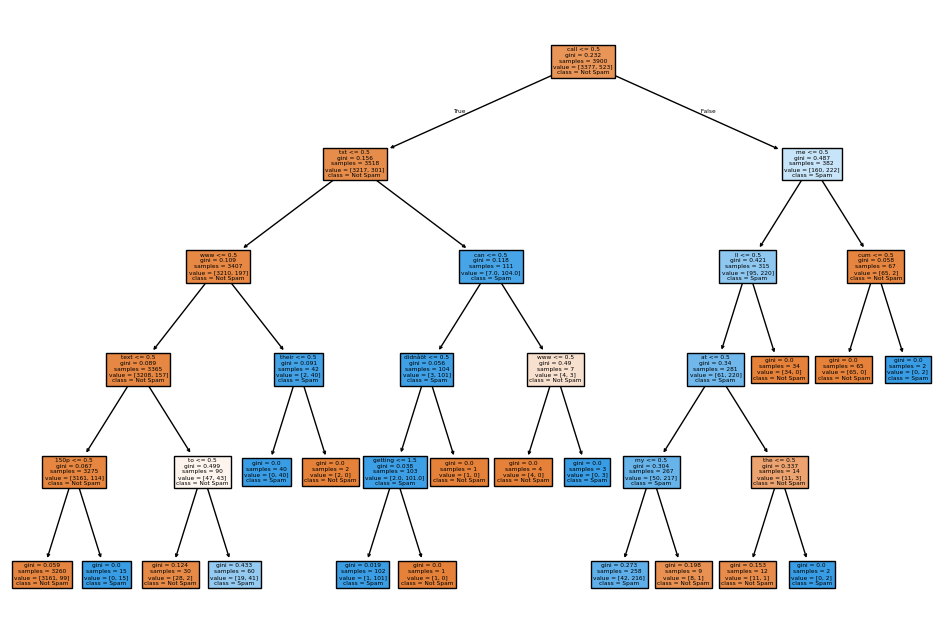

In [13]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))
plot_tree(clf, feature_names=vectorizer.get_feature_names_out(), class_names=['Not Spam', 'Spam'], filled=True)
plt.show()